# Inconsistencies and extreme values

Identify and treat values that contradict other information
(inconsistencies) or are unusually large (extreme values). The input is
`../data/processed/student_data_preprocessed.csv`, produced by
`data_preprocessing.ipynb`; run from the `notebooks/` directory.

**Contents**
1. Setup
2. Overview figures
3. Issues and status
4. Grades
5. Travel time
6. Extreme values
7. Summary of changes

---

## 1. Setup

### Environment check

Records the Python and pandas versions and the working directory.

In [1]:
import sys
import os
import pandas as pd

print(sys.version)
print(os.getcwd())
print(pd.__version__)

3.14.3 (main, Feb  3 2026, 15:32:20) [Clang 17.0.0 (clang-1700.6.3.2)]
/Users/yassir/Data-Mining-Project/notebooks
3.0.6


### Load the prepared dataset

The student identifier is used as the index, and the literal education
category "None" is kept distinct from missing values.

In [2]:
student_data = pd.read_csv(
    '../data/processed/student_data_preprocessed.csv',
    index_col='student_row_id',
    keep_default_na=False,
    na_values=['']
)

student_data.shape

(649, 33)

### Checks on the prepared dataset

All 649 students, no missing values, and unique identifiers.

In [3]:
assert student_data.shape == (649, 33)
assert student_data.isna().sum().sum() == 0
assert student_data.index.is_unique

### Working copy

Treatments are applied to `student_data_treated`; `student_data` keeps the
prepared values for comparison.

In [4]:
student_data_treated = student_data.copy()

student_data_treated.shape

(649, 33)

---

## 2. Overview figures

The data is plotted before any value is questioned. Values that stand out
are drawn in orange, all other students in blue.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

regular_colour = '#2a78d6'
flagged_colour = '#eb6834'

# Small random offsets separate students with identical values in scatterplots
rng = np.random.default_rng(42)

### Grades across the three periods

Each point is a student; points are spread slightly so that identical
grades remain visible.

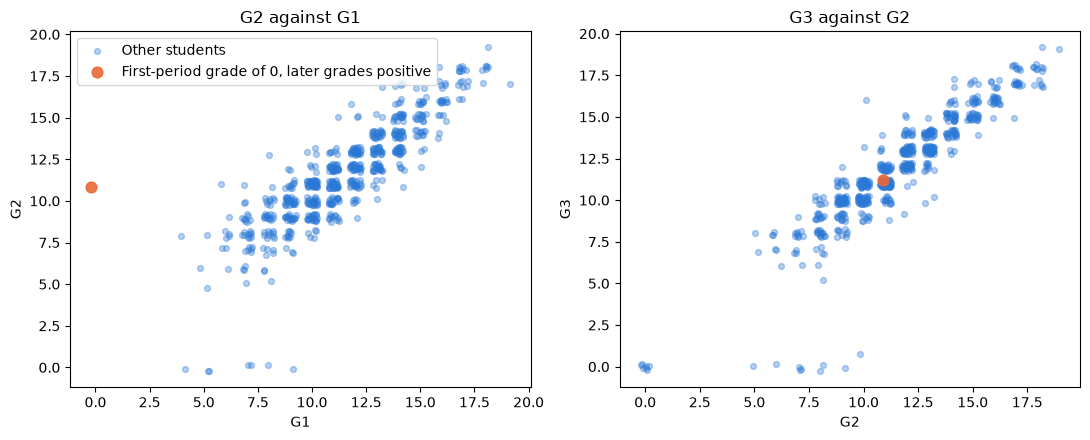

In [6]:
inconsistent_first_grade = (
    student_data['G1'].eq(0) & student_data['G2'].gt(0) & student_data['G3'].gt(0)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (x_grade, y_grade) in zip(axes, [('G1', 'G2'), ('G2', 'G3')]):
    for flagged, colour, label in [
        (False, regular_colour, 'Other students'),
        (True, flagged_colour, 'First-period grade of 0, later grades positive')
    ]:
        group = student_data[inconsistent_first_grade == flagged]
        ax.scatter(
            group[x_grade] + rng.uniform(-0.25, 0.25, len(group)),
            group[y_grade] + rng.uniform(-0.25, 0.25, len(group)),
            s=18 if not flagged else 60,
            color=colour,
            alpha=0.35 if not flagged else 0.9,
            label=label
        )
    ax.set_xlabel(x_grade)
    ax.set_ylabel(y_grade)
    ax.set_title(f'{y_grade} against {x_grade}')

axes[0].legend(loc='upper left')
plt.tight_layout()
plt.show()

**Observation:** one student stands out with a first-period grade of 0
followed by 11 in both later periods. Fifteen students fall to 0 in the
later periods and do not recover (section 4).

### Travel time by school and residence

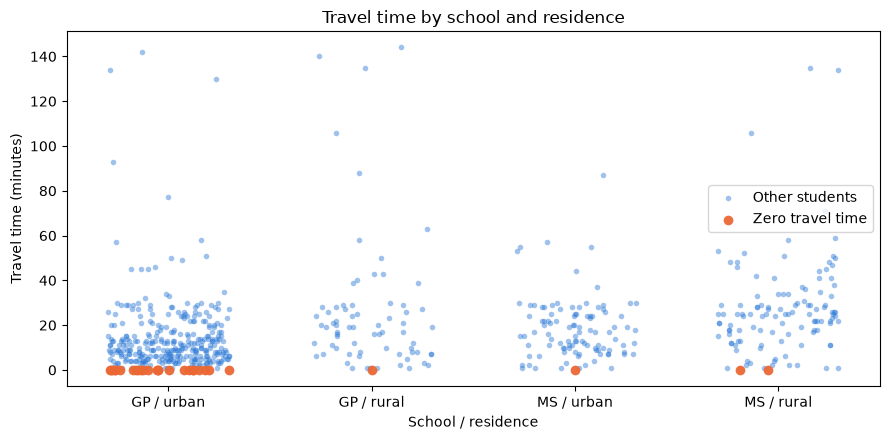

In [7]:
travel_plot_data = student_data.loc[student_data['address'] != 'unknown'].assign(
    Group=lambda data: data['school'] + ' / ' + data['address'].map({'U': 'urban', 'R': 'rural'})
)
group_order = ['GP / urban', 'GP / rural', 'MS / urban', 'MS / rural']
zero_travel_point = travel_plot_data['traveltime'].eq(0)

plt.figure(figsize=(9, 4.5))

# Other students first, then zero travel times drawn on top
sns.stripplot(
    data=travel_plot_data[~zero_travel_point], x='Group', y='traveltime',
    order=group_order, color=regular_colour, jitter=0.3, size=4, alpha=0.45,
    label='Other students'
)
sns.stripplot(
    data=travel_plot_data[zero_travel_point], x='Group', y='traveltime',
    order=group_order, color=flagged_colour, jitter=0.3, size=7, alpha=0.95,
    label='Zero travel time'
)

handles, labels = plt.gca().get_legend_handles_labels()
unique = dict(zip(labels, handles))
plt.legend(unique.values(), unique.keys())

plt.xlabel('School / residence')
plt.ylabel('Travel time (minutes)')
plt.title('Travel time by school and residence')
plt.tight_layout()
plt.show()

**Observation:** 29 students record a travel time of 0, mostly urban
students at GP (24); one rural student at GP and three students at MS also
record 0, where journeys usually take 17 to 25 minutes (section 5).

### Study time, travel time, and absences

Separate boxplots, because the units differ. Points beyond the whiskers
(more than 1.5 × IQR above the box) are drawn in orange.

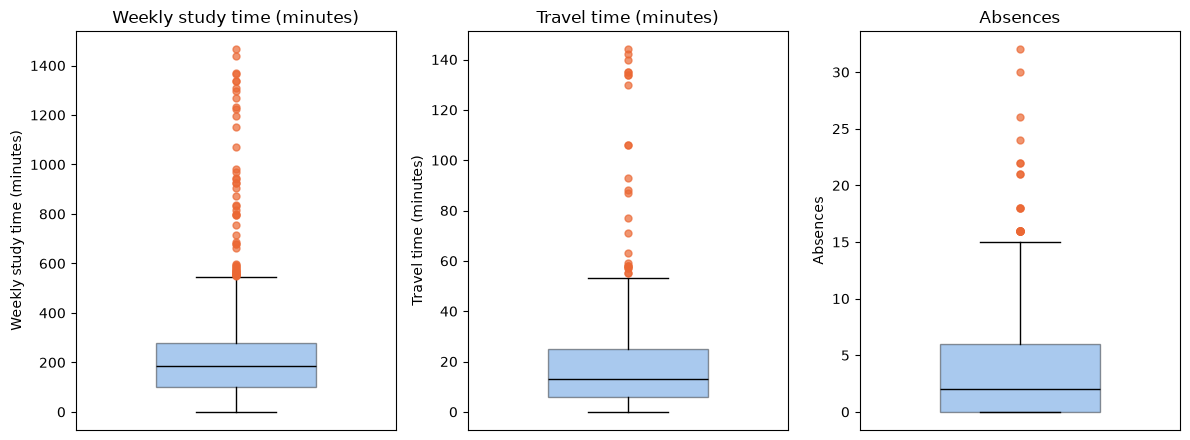

In [8]:
extreme_columns = {
    'studytime': 'Weekly study time (minutes)',
    'traveltime': 'Travel time (minutes)',
    'absences': 'Absences'
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))

for ax, (column, label) in zip(axes, extreme_columns.items()):
    ax.boxplot(
        student_data[column],
        widths=0.5,
        patch_artist=True,
        boxprops={'facecolor': regular_colour, 'alpha': 0.4},
        medianprops={'color': 'black'},
        flierprops={'marker': 'o', 'markerfacecolor': flagged_colour,
                    'markeredgecolor': flagged_colour, 'markersize': 5, 'alpha': 0.7}
    )
    ax.set_xticks([])
    ax.set_ylabel(label)
    ax.set_title(label)

plt.tight_layout()
plt.show()

**Observation:** values beyond the upper whisker appear in all three
variables: 53 study times above 547 minutes (up to 1465), 24 travel times
above about 54 minutes (up to 144), and 20 absence counts above 15 (up to
32). These extreme values are treated in section 6.

---

## 3. Issues and status

Issues identified in the figures of section 2.

| Type | Issue | Seen in | Students | Status |
| :--- | :--- | :--- | :--- | :--- |
| Inconsistency | First-period grade of 0, then G2 = G3 = 11 | Grades | 1 | Kept unchanged (section 4) |
| Inconsistency | Travel time of 0 minutes | Travel time | 29 | 4 values replaced (section 5) |
| Extreme value | Study time above 547 minutes (up to 1465) | Boxplots | 53 | Pending (section 6) |
| Extreme value | Travel time above about 54 minutes (up to 144) | Boxplots | 24 | Pending (section 6) |
| Extreme value | Absences above 15 (up to 32) | Boxplots | 20 | Pending (section 6) |

**Other observations:** implausible family sizes (0 and 1) are treated in
`data_preprocessing.ipynb`. Four parents recorded as teachers have only
Primary or Secondary education; this is noted only, as parental variables
describe the clusters rather than form them.

---

## 4. Grades

### Zero grades

In [9]:
grade_columns = ['G1', 'G2', 'G3']

zero_grades = student_data[grade_columns].eq(0)

zero_pattern = (
    zero_grades['G1'].map({True: '0', False: '+'}) + ' '
    + zero_grades['G2'].map({True: '0', False: '+'}) + ' '
    + zero_grades['G3'].map({True: '0', False: '+'})
)

student_data.loc[zero_grades.any(axis=1), grade_columns + ['failures']].assign(
    Pattern=zero_pattern
).sort_values('Pattern')

,G1,G2,G3,failures,Pattern
student_row_id,,,,,
163,11,9,0,2.0,+ + 0
519,8,7,0,0.0,+ + 0
583,8,6,0,1.0,+ + 0
586,8,8,0,0.0,+ + 0
626,7,5,0,0.0,+ + 0
637,7,7,0,0.0,+ + 0
639,5,8,0,1.0,+ + 0
640,7,7,0,1.0,+ + 0
440,7,0,0,0.0,+ 0 0


Sixteen students have a zero grade, in three patterns: "0 + +" (1),
"+ 0 0" (7), and "+ + 0" (8). Only the first student's grades recover after
the zero.

### Is the final grade calculated from the earlier grades?

In [10]:
positive_grades = student_data.loc[(student_data[grade_columns] > 0).all(axis=1)]

earlier_grades = positive_grades[['G1', 'G2']]
final_grade = positive_grades['G3']

grade_comparison = pd.Series({
    'G3 equals the average of G1 and G2 (rounded)': (
        (final_grade - earlier_grades.mean(axis=1)).abs().le(0.5).mean()
    ),
    'G3 equals the higher of G1 and G2': final_grade.eq(earlier_grades.max(axis=1)).mean(),
    'G3 equals G2': final_grade.eq(positive_grades['G2']).mean(),
    'G3 above both G1 and G2': final_grade.gt(earlier_grades.max(axis=1)).mean()
}, name='Students (%)') * 100

grade_comparison.round(1)

G3 equals the average of G1 and G2 (rounded)    57.0
G3 equals the higher of G1 and G2               45.5
G3 equals G2                                    44.1
G3 above both G1 and G2                         31.1
Name: Students (%), dtype: float64

No: the closest rule, the average of G1 and G2, fits only 57.0% of
students, and 31.1% score higher in G3 than in both earlier periods. G3 is a
separate assessment, so an earlier grade cannot be reconstructed; as the
grade that decides the year, it represents performance in the clustering.

### Past failures and zero grades

Missing failure counts were set to 0 in preprocessing.

In [11]:
grade_group = zero_pattern.where(zero_grades.any(axis=1), 'No zero grade')

(student_data['failures'] > 0).groupby(grade_group).mean().mul(100).round(1).rename(
    'With a past failure (%)'
)

+ + 0            50.0
+ 0 0            57.1
0 + +             0.0
No zero grade    14.2
Name: With a past failure (%), dtype: float64

Students whose grades fall to zero and stay there failed before far more
often (50.0% and 57.1%) than other students (14.2%).

### Does `failures` count this year's failed periods?

If so, it would equal the number of grades below 10, the pass mark.

In [12]:
grades_below_ten = (student_data[grade_columns] < 10).sum(axis=1).rename(
    'Grades below 10'
)

pd.crosstab(student_data['failures'].astype(int), grades_below_ten)

Grades below 10,0,1,2,3
failures,,,,
0,431,55,25,40
1,17,15,10,27
2,2,3,4,7
3,1,1,5,6


No: the counts rarely agree. Twenty students with past failures passed
every period (row 170 has three failures and grades of 11, 10, 11), and 120
students without past failures failed at least once. `failures` most
plausibly counts earlier years and is left unchanged.

### Decisions on zero grades

- **Row 0 (0, 11, 11): kept unchanged.** The 0 is unlikely to be a real
  score (possibly a transfer, a missed assessment, or a recording error), but
  it is a single case, G1 does not form the clusters, and no replacement can
  be derived.
- **Zeros that continue to the end (15 students): kept.** They are not an
  inconsistency but students who most likely left or stopped being assessed,
  the students a school most needs to identify.

Noted for the cluster profiles: these 15 students had missing absences (set
to 0, probably inaccurate), and 14 of them attend MS.

---

## 5. Travel time

### Zero travel times

In [13]:
zero_travel = student_data['traveltime'] == 0

student_data.loc[zero_travel].groupby(['school', 'address']).size()

school  address
GP      R           1
        U          24
        unknown     1
MS      R           2
        U           1
dtype: int64

In [14]:
student_data['traveltime'].value_counts().sort_index().head(7)

traveltime
0.0    29
1.0    30
2.0    15
3.0    20
4.0    24
5.0    22
6.0    29
Name: count, dtype: int64

A travel time of 0 is about as common as 1 minute, so it plausibly records a
journey of under a minute. Twenty-four of the 29 zeros are urban students at
GP.

### Where is each school located?

Inferred from the students with a recorded address, checked against their
travel times.

In [15]:
known_address = student_data['address'] != 'unknown'

school_composition = pd.crosstab(
    student_data.loc[known_address, 'school'],
    student_data.loc[known_address, 'address'],
    normalize='index'
).mul(100).round(1)

school_composition

address,R,U
school,,
GP,17.5,82.5
MS,53.2,46.8


In [16]:
student_data.loc[known_address].groupby(['school', 'address'])['traveltime'].median().unstack()

address,R,U
school,,
GP,19.0,9.0
MS,25.0,17.0


GP is an urban school: 82.5% of its students are urban and travel 9
minutes, against 19 for its rural students. MS is evenly split (53.2% rural),
so its setting is uncertain.

### Zero travel times outside urban GP students

In [17]:
student_data.loc[
    zero_travel & ~(student_data['school'].eq('GP') & student_data['address'].eq('U')),
    ['school', 'address', 'reason', 'traveltime']
]

,school,address,reason,traveltime
student_row_id,,,,
169,GP,R,reputation,0.0
394,GP,unknown,home,0.0
442,MS,R,reputation,0.0
443,MS,R,reputation,0.0
546,MS,U,course,0.0


### Decision

- **Kept:** the 24 urban GP students, plausible near an urban school, and
  row 394, which chose GP because it is close to home.
- **Replaced:** rows 169 (GP, rural), 442 and 443 (MS, rural), and 546 (MS,
  urban), whose groups usually travel 17 to 25 minutes. Each receives the
  median travel time of the other students from the same school and
  residence type.

In [18]:
replaced_zero_travel = zero_travel & (
    (student_data['school'].eq('GP') & student_data['address'].eq('R'))
    | student_data['school'].eq('MS')
)

group_travel_median = (
    student_data['traveltime']
    .where(~replaced_zero_travel)
    .groupby([student_data['school'], student_data['address']])
    .transform('median')
)

student_data_treated.loc[replaced_zero_travel, 'traveltime'] = (
    group_travel_median[replaced_zero_travel]
)

student_data_treated.loc[replaced_zero_travel, ['school', 'address', 'traveltime']]

,school,address,traveltime
student_row_id,,,
169,GP,R,19.0
442,MS,R,25.0
443,MS,R,25.0
546,MS,U,17.0


### Validation of travel-time treatment

In [19]:
changed_travel = student_data_treated['traveltime'] != student_data['traveltime']

assert changed_travel.sum() == 4
assert changed_travel.equals(replaced_zero_travel)
assert student_data_treated.loc[replaced_zero_travel, 'traveltime'].equals(
    group_travel_median[replaced_zero_travel]
)
assert student_data_treated['traveltime'].eq(0).sum() == 25
assert student_data_treated.drop(columns='traveltime').equals(
    student_data.drop(columns='traveltime')
)

print('Travel times changed:', changed_travel.sum())

Travel times changed: 4


---

## 6. Extreme values

These values may be true, so each variable is treated separately. Options
include keeping, capping (e.g. at the whisker), transforming, or removing
them; the course notebooks show boxplot detection and removal.

*Treatment pending.*

---

## 7. Summary of changes

In [20]:
changed_values = (student_data_treated != student_data).sum()

changed_values[changed_values > 0].rename('Values changed')

traveltime    4
Name: Values changed, dtype: int64

| Section | Change |
| :--- | :--- |
| 4. Grades | None (zero grades reviewed and kept) |
| 5. Travel time | 4 zero travel times replaced with their group median |
| 6. Extreme values | Pending |

The treated dataset will be saved once the extreme values are treated.